## Step 1

This step imports the libraries 

In [11]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping
print("Libraries aready imported sucessfull")

Libraries aready imported sucessfull


## Step 2

This step loads the dataset  and displays the first five recods

In [35]:
# (a) Load the dataset 
df = pd.read_csv("dataset/train.csv")

# (b) First 5 records
df.head()

,id,annual_income,debt_to_income_ratio,credit_score,loan_amount,interest_rate,gender,marital_status,education_level,employment_status,loan_purpose,grade_subgrade,loan_paid_back
0,0,29367.99,0.084,736,2528.42,13.67,Female,Single,High School,Self-employed,Other,C3,1.0
1,1,22108.02,0.166,636,4593.10,12.92,Male,Married,Master's,Employed,Debt consolidation,D3,0.0
2,2,49566.20,0.097,694,17005.15,9.76,Male,Single,High School,Employed,Debt consolidation,C5,1.0
3,3,46858.25,0.065,533,4682.48,16.10,Female,Single,High School,Employed,Debt consolidation,F1,1.0
4,4,25496.70,0.053,665,12184.43,10.21,Male,Married,High School,Employed,Other,D1,1.0


## Step 3
this step checks the dataset size, target labels, and missing values

In [25]:
# (a) Shape
print("Shape (rows, columns):", df.shape)

# (b) Unique values of the target
print("\nUnique values of loan_paid_back:", df["loan_paid_back"].unique())

# (c) Missing values per column
print("\nMissing values per column:")
print(df.isnull().sum())

original_rows = df.shape[0]  

Shape (rows, columns): (593994, 13)

Unique values of loan_paid_back: [1. 0.]

Missing values per column:
id                      0
annual_income           0
debt_to_income_ratio    0
credit_score            0
loan_amount             0
interest_rate           0
gender                  0
marital_status          0
education_level         0
employment_status       0
loan_purpose            0
grade_subgrade          0
loan_paid_back          0
dtype: int64


## Step 4

This step counts and visualizing the two target classes: `0` means the loan was not paid back and  while `1` means it was paid back

loan_paid_back
1.0    474494
0.0    119500
Name: count, dtype: int64

Percentages:
loan_paid_back
1.0    79.881952
0.0    20.118048
Name: proportion, dtype: float64


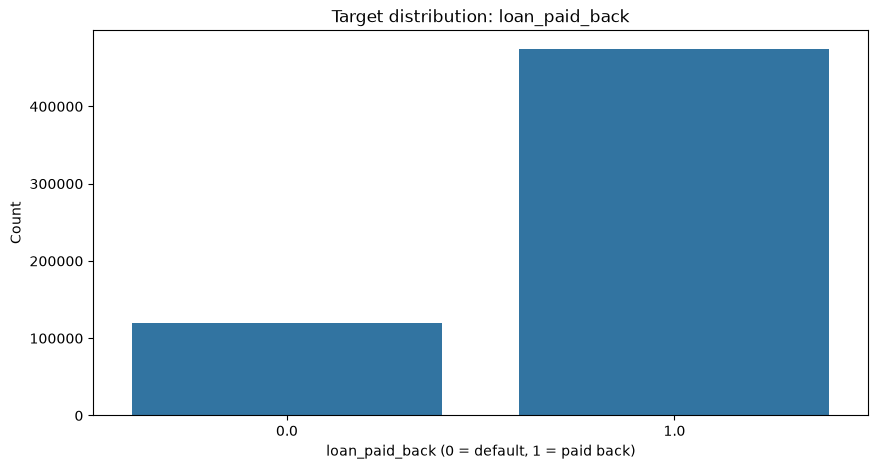

In [ ]:
print(df["loan_paid_back"].value_counts())
print("\nPercentages:")
print(df["loan_paid_back"].value_counts(normalize=True) * 100)

plt.figure(figsize=(10, 5))
sns.countplot(x="loan_paid_back", data=df)
plt.title("Target distribution: loan_paid_back")
plt.xlabel("Loan_paid_back (0 = default, 1 = paid back)")
plt.ylabel("Count")
plt.show()

## Step 5

This step uses IQR rule to identify outliers in numeric features, counts them, and displays dataframe rows containing  outlier.

In [34]:
# Numeric columns only (id is just an identifier and loan_paid_back is the target, so both are excluded)
numeric_cols = [c for c in df.select_dtypes(include=[np.number]).columns
                if c not in ["id", "loan_paid_back"]]

# IQR bounds
Q1 = df[numeric_cols].quantile(0.25)
Q3 = df[numeric_cols].quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# True where a value is an outlier
outlier_mask = (df[numeric_cols] < lower_bound) | (df[numeric_cols] > upper_bound)

# (a) Total number of outlier values
print("(a) Total number of outlier values:", int(outlier_mask.sum().sum()))

# (b) Outliers per numeric column
print("\n(b) Outliers per numeric column:")
print(outlier_mask.sum())

# (c) Rows with at least one outlier
rows_with_outlier = outlier_mask.any(axis=1)
print("\n(c) Number of rows with at least one outlier:", int(rows_with_outlier.sum()))
display(df[rows_with_outlier].head())

# (d) DataFrame containing all outlier rows
outlier_df = df[rows_with_outlier]
print("\n(d) Outlier rows dataframe shape:", outlier_df.shape)
outlier_df

(a) Total number of outlier values: 47412

(b) Outliers per numeric column:
annual_income           15917
debt_to_income_ratio    17556
credit_score             5901
loan_amount              2902
interest_rate            5136
dtype: int64

(c) Number of rows with at least one outlier: 45437


,id,annual_income,debt_to_income_ratio,credit_score,loan_amount,interest_rate,gender,marital_status,education_level,employment_status,loan_purpose,grade_subgrade,loan_paid_back
3,3,46858.25,0.065,533,4682.48,16.10,Female,Single,High School,Employed,Debt consolidation,F1,1.0
22,22,135416.72,0.160,661,12404.14,13.30,Male,Single,High School,Unemployed,Debt consolidation,D1,0.0
26,26,24001.73,0.284,669,13863.79,10.88,Female,Married,Master's,Employed,Debt consolidation,D4,0.0
30,30,15557.19,0.152,591,15257.87,17.76,Male,Married,High School,Employed,Education,E5,1.0
36,36,48602.37,0.091,531,13379.10,15.67,Male,Married,Bachelor's,Unemployed,Debt consolidation,F4,0.0



(d) Outlier rows dataframe shape: (45437, 13)


,id,annual_income,debt_to_income_ratio,credit_score,loan_amount,interest_rate,gender,marital_status,education_level,employment_status,loan_purpose,grade_subgrade,loan_paid_back
3,3,46858.25,0.065,533,4682.48,16.10,Female,Single,High School,Employed,Debt consolidation,F1,1.0
22,22,135416.72,0.160,661,12404.14,13.30,Male,Single,High School,Unemployed,Debt consolidation,D1,0.0
26,26,24001.73,0.284,669,13863.79,10.88,Female,Married,Master's,Employed,Debt consolidation,D4,0.0
30,30,15557.19,0.152,591,15257.87,17.76,Male,Married,High School,Employed,Education,E5,1.0
36,36,48602.37,0.091,531,13379.10,15.67,Male,Married,Bachelor's,Unemployed,Debt consolidation,F4,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
593919,593919,52233.83,0.284,699,16686.17,15.67,Female,Single,PhD,Employed,Debt consolidation,C1,1.0
593934,593934,51139.38,0.357,717,22458.69,11.54,Male,Single,High School,Employed,Other,C5,1.0
593948,593948,160982.65,0.102,723,8090.90,7.21,Female,Married,Bachelor's,Employed,Debt consolidation,C3,1.0
593965,593965,14798.35,0.061,522,27995.88,17.62,Male,Married,High School,Employed,Debt consolidation,F4,1.0


## Step 6

This step draws boxplots for numeric features to visualize outliers

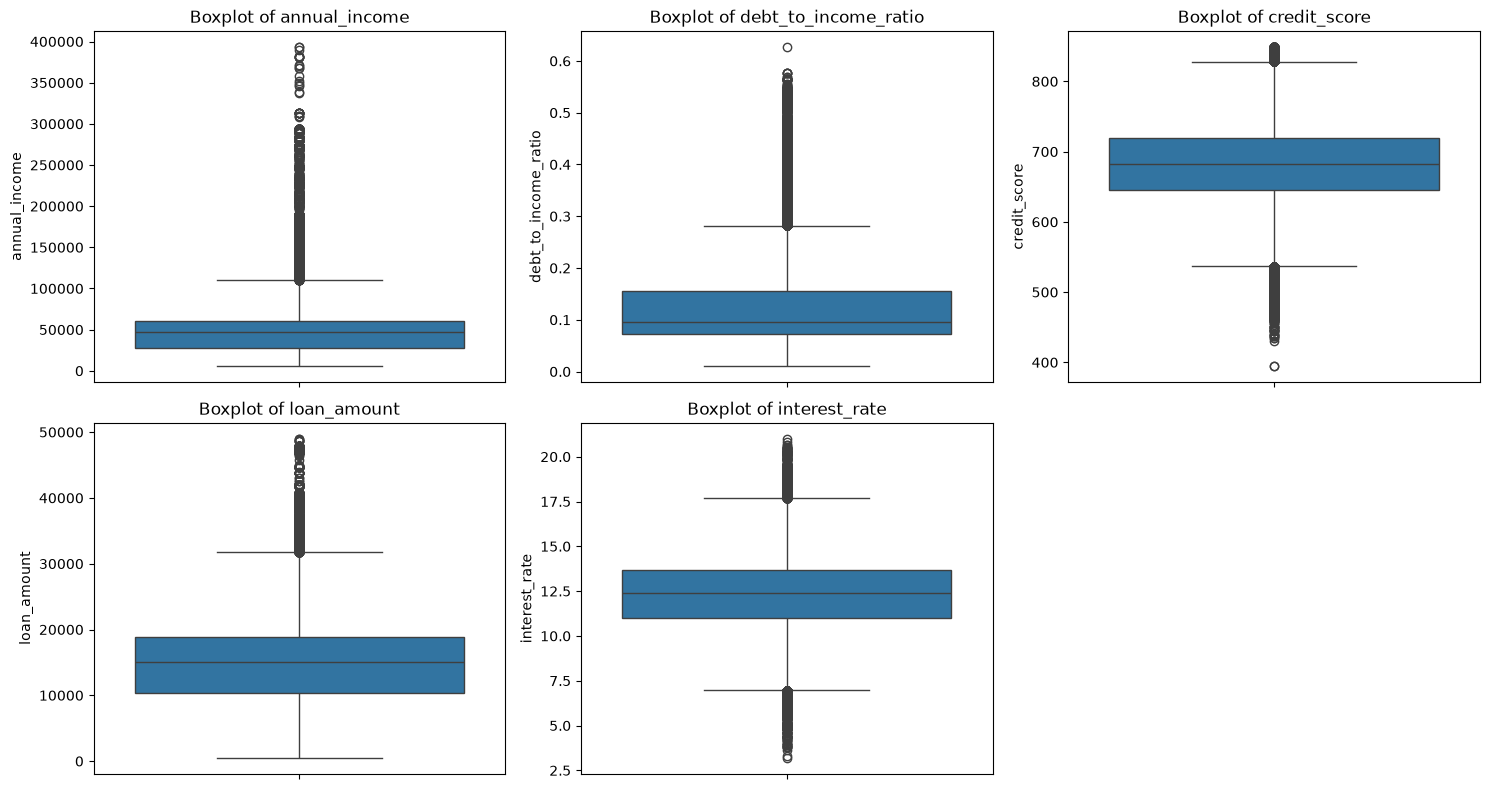

In [28]:
n = len(numeric_cols)
cols = 3
rows = int(np.ceil(n / cols))
fig, axes = plt.subplots(rows, cols, figsize=(5 * cols, 4 * rows))
axes = np.array(axes).flatten()

for i, col in enumerate(numeric_cols):
    sns.boxplot(y=df[col], ax=axes[i])
    axes[i].set_title(f"Boxplot of {col}")

for j in range(n, len(axes)):
    axes[j].axis("off")

plt.tight_layout()
plt.show()

## Step 7

This step removes detected outlier and compares the dataset size before and after cleaning.

In [29]:
# (a) Remove all outlier rows using the IQR bounds
df_clean = df[~rows_with_outlier].reset_index(drop=True)

# (b) New shape
print("Shape before outlier removal:", df.shape)
print("Shape after outlier removal :", df_clean.shape)

cleaned_rows = df_clean.shape[0]   

Shape before outlier removal: (593994, 13)
Shape after outlier removal : (548557, 13)


## Step 8

This is plots correlations matrix for numerical feauture using heatmap

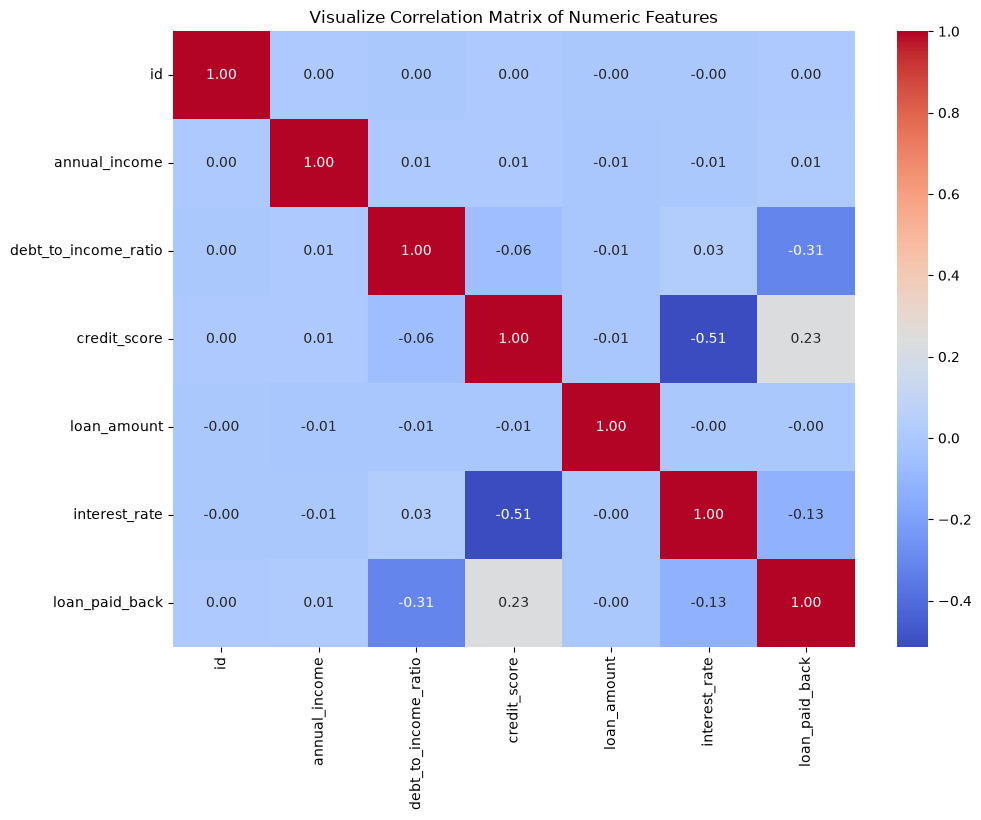

In [30]:
corr_matrix = df_clean.select_dtypes(include=[np.number]).corr()

plt.figure(figsize=(11, 8))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Visualize Correlation Matrix of Numeric Features")
plt.show()

## Step 9

This step removes the `id` column because it is  identifier rather than a useful loan-repayment feature, then checks the remaining columns.

In [31]:
df_clean = df_clean.drop(columns=["id"])
print("'id' still in dataframe?", "id" in df_clean.columns)
print("Columns:", list(df_clean.columns))

'id' still in dataframe? False
Columns: ['annual_income', 'debt_to_income_ratio', 'credit_score', 'loan_amount', 'interest_rate', 'gender', 'marital_status', 'education_level', 'employment_status', 'loan_purpose', 'grade_subgrade', 'loan_paid_back']


## Step 10

This step finds categorical columns and converts their categories into numeric labels using `LabelEncoder`, so the ANN can process them.

In [32]:
# (a) Categorical features
categorical_cols = df_clean.select_dtypes(include=["object", "category"]).columns.tolist()
print("(a) Categorical features:", categorical_cols)

# (b) + (c) Label encode each categorical column and update the SAME columns
label_encoders = {}
for col in categorical_cols:
    le = LabelEncoder()
    df_clean[col] = le.fit_transform(df_clean[col])
    label_encoders[col] = le

# (d) First 5 records
df_clean.head()

(a) Categorical features: ['gender', 'marital_status', 'education_level', 'employment_status', 'loan_purpose', 'grade_subgrade']


,annual_income,debt_to_income_ratio,credit_score,loan_amount,interest_rate,gender,marital_status,education_level,employment_status,loan_purpose,grade_subgrade,loan_paid_back
0,29367.99,0.084,736,2528.42,13.67,0,2,1,2,6,12,1.0
1,22108.02,0.166,636,4593.10,12.92,1,1,2,0,2,17,0.0
2,49566.20,0.097,694,17005.15,9.76,1,2,1,0,2,14,1.0
3,25496.70,0.053,665,12184.43,10.21,1,1,1,0,6,15,1.0
4,44940.30,0.058,653,12159.92,12.24,1,2,0,0,6,15,1.0


## Step 11

This step separates the input features (`X`) from the target (`y`). The features are used to make predictions, and `loan_paid_back` is the value the model learns to predict.

In [36]:
X = df_clean.drop(columns=["loan_paid_back"])
y = df_clean["loan_paid_back"]
print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (548557, 11)
y shape: (548557,)


## Step 12

This step divides the cleaned data into 80% training data and 20% test data. `stratify=y` preserves the target-class proportions, while `random_state=42` makes the split reproducible

In [37]:
# (a) Train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print("X_train:", X_train.shape)
print("X_test :", X_test.shape)
print("y_train:", y_train.shape)
print("y_test :", y_test.shape)

# (b) Notice 1 and Notice 2
total_split = len(X_train) + len(X_test)
print("\nlen(X_train) + len(X_test) =", total_split)
print("Rows after outlier removal (Step 7) =", cleaned_rows)
print("Original rows (Step 3)              =", original_rows)

print("Notice 1 (equals Step 7 rows)      :", total_split == cleaned_rows)
print("Notice 2 (differs from Step 3 rows):", total_split != original_rows)
assert total_split == cleaned_rows and total_split != original_rows, "Review your work!"

X_train: (438845, 11)
X_test : (109712, 11)
y_train: (438845,)
y_test : (109712,)

len(X_train) + len(X_test) = 548557
Rows after outlier removal (Step 7) = 548557
Original rows (Step 3)              = 593994
Notice 1 (equals Step 7 rows)      : True
Notice 2 (differs from Step 3 rows): True


## Step 13

This step standardizes features using the training data's mean and standard deviation. The same scaler transforms the test data to avoid fitting preprocessing on the test set.

In [38]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)   # fit on training data ONLY
X_test_scaled = scaler.transform(X_test)         # only transform test data

print("X_train_scaled:", X_train_scaled.shape)
print("X_test_scaled :", X_test_scaled.shape)

X_train_scaled: (438845, 11)
X_test_scaled : (109712, 11)


## Step 14

This step builds a feed-forward ANN with ReLU hidden layers, Dropout to help reduce overfitting, and a sigmoid output for binary classification. Adam optimizes the model, binary cross-entropy measures its error, and accuracy is tracked.

In [40]:
model = Sequential([
    Input(shape=(X_train_scaled.shape[1],)),
    Dense(64, activation="relu"),
    Dropout(0.2),
    Dense(32, activation="relu"),
    Dropout(0.2),
    Dense(16, activation="relu"),
    Dense(1, activation="sigmoid")      # binary classification
])

model.compile(optimizer="adam",
              loss="binary_crossentropy",
              metrics=["accuracy"])

model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_4 (Dense)                 │ (None, 64)             │           768 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,393 (13.25 KB)

 Trainable params: 3,393 (13.25 KB)

 Non-trainable params: 0 (0.00 B)

## Step 15

This step trains the ANN for up to 30 epochs. Early stopping monitors validation loss and stops training if it does not improve for five epochs, restoring the best weights.

In [41]:
early_stop = EarlyStopping(monitor="val_loss",
                           patience=5,
                           restore_best_weights=True)

history = model.fit(
    X_train_scaled, y_train,
    epochs=30,
    validation_split=0.2,
    batch_size=512,
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/30
686/686 ━━━━━━━━━━━━━━━━━━━━ 6s 5ms/step - accuracy: 0.8862 - loss: 0.2993 - val_accuracy: 0.9059 - val_loss: 0.2583
Epoch 2/30
686/686 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.9061 - loss: 0.2608 - val_accuracy: 0.9065 - val_loss: 0.2542
Epoch 3/30
686/686 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.9071 - loss: 0.2564 - val_accuracy: 0.9066 - val_loss: 0.2529
Epoch 4/30
686/686 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.9074 - loss: 0.2544 - val_accuracy: 0.9068 - val_loss: 0.2529
Epoch 5/30
686/686 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.9078 - loss: 0.2533 - val_accuracy: 0.9067 - val_loss: 0.2524
Epoch 6/30
686/686 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.9078 - loss: 0.2526 - val_accuracy: 0.9068 - val_loss: 0.2527
Epoch 7/30
686/686 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.9080 - loss: 0.2524 - val_accuracy: 0.9067 - val_loss: 0.2526
Epoch 8/30
686/686 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.9079 - loss: 0.2519 - val_accuracy: 0.

## Step 16

This step evaluates the trained model on both training and test data and  Comparing their accuracy helps assess performance on unseen data and may reveal overfitting.

In [42]:
train_loss, train_acc = model.evaluate(X_train_scaled, y_train, verbose=0)
test_loss, test_acc = model.evaluate(X_test_scaled, y_test, verbose=0)

print(f"(a) Train accuracy: {train_acc:.4f}")
print(f"(b) Test accuracy : {test_acc:.4f}")

(a) Train accuracy: 0.9083
(b) Test accuracy : 0.9080


## Step 17

This step predicts repayment probabilities for the test set and converts them into class labels using a 0.5 threshold: probabilities above 0.5 become class `1`; otherwise they become class `0`.

In [43]:
# (a) Probabilities
y_pred_proba = model.predict(X_test_scaled)

# (b) Binary predictions with threshold 0.5
y_pred = (y_pred_proba > 0.5).astype(int)

print("First 5 probabilities:", y_pred_proba[:5].flatten())
print("First 5 predictions  :", y_pred[:5].flatten())

3429/3429 ━━━━━━━━━━━━━━━━━━━━ 4s 1ms/step
First 5 probabilities: [0.95177585 0.97932714 0.992368   0.9339372  0.9351052 ]
First 5 predictions  : [1 1 1 1 1]


## Step 18

This step places the actual test labels, predicted labels, and predicted probabilities side by side so you can inspect individual predictions.

In [44]:
comparison = pd.DataFrame({
    "Actual": y_test.values,
    "Predicted": y_pred.flatten(),
    "Probabilities": y_pred_proba.flatten()
})
comparison.head(20)

,Actual,Predicted,Probabilities
0,0.0,1,0.951776
1,1.0,1,0.979327
2,1.0,1,0.992368
3,1.0,1,0.933937
4,1.0,1,0.935105
5,1.0,1,0.959306
6,0.0,1,0.646255
7,0.0,0,0.027380
8,0.0,1,0.711033
9,1.0,1,0.986301


## Step 19


The final model accuracy (test accuracy) contributes 100% of the marks. Test accuracy is converted into a mark out of 30 using the formula below.

**Marks /30 = (n * 30) / 100**, where n = test accuracy in %.

In [46]:
n = test_acc * 100
marks = (n * 30) / 100
print(f"Test Accuracy (n) = {n:.2f}%")
print(f"Marks = ({n:.2f} * 30) / 100 = {marks:.2f} / 30")

Test Accuracy (n) = 90.80%
Marks = (90.80 * 30) / 100 = 27.24 / 30
